In [ ]:
'''
looking at csv files of lightcurves that we disagree on for random forest training
'''

In [1]:
import numpy as np
import pandas as pd
from astropy.io import fits
import matplotlib.pyplot as plt
import precision_recall as pr
import gc  # garbage collector
import review_findings_functions as rff
import os
import importlib
import implantation_functions as imp
# import corner
# from astropy.wcs import WCS
# import shutil
# from astroquery.gaia import Gaia
# from astropy.coordinates import SkyCoord
# import astropy.units as u
plt.rcParams["image.interpolation"] = "nearest"
plt.rcParams["image.cmap"] = "gist_gray"

In [2]:
labels = pd.read_csv('/lustre/lrspec/ZTF_data/random_forest_training/group_labels.csv',index_col=0)

In [13]:
ourlabels = labels[(labels[['0','1','2']].sum(axis=1)<3)*(labels[['0','1','2']].sum(axis=1)>0)]

In [33]:
lcfpath='/lustre/lrspec/ZTF_data/lightcurves/1020_filtered/'
lcpath='/lustre/lrspec/ZTF_data/lightcurves/1020/'

In [62]:
from tqdm.auto import tqdm

In [71]:
plt.rcParams["figure.figsize"] = (10, len(ourlabels))


In [82]:
# fig.savefig('/lustre/lrspec/ZTF_data/lc_disagreements.pdf')

0it [00:00, ?it/s]

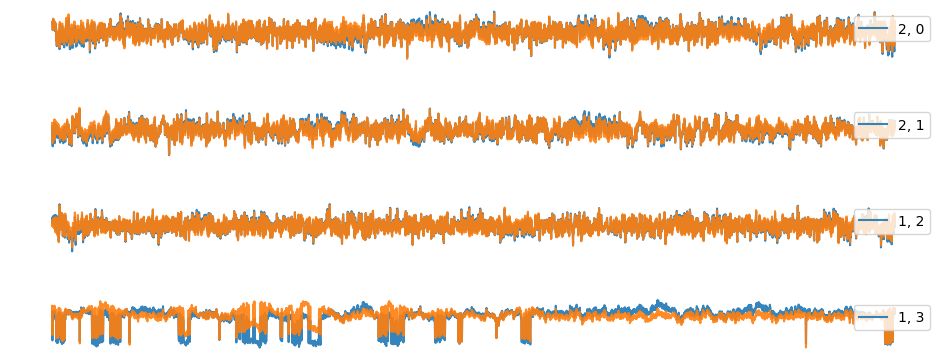

In [81]:
fig, ax = plt.subplots(len(ourlabels)) #len(ourlabels)
plt.tight_layout()
axs = ax.ravel()
for i, (idx,row) in tqdm(enumerate(ourlabels.iterrows())):
    # print(row[[0,1,2]].values.sum())
    lc_unfiltered = pd.read_csv(lcpath+row.name)['flux_hap_2'].values
    lc_filtered = pd.read_csv(lcfpath+row.name[:-4]+'_filtered_hap2.csv')['flux_hap_2'].values
    # print(lc_filtered.iloc[0])
    
    axs[i].plot(lc_unfiltered, label=str(row[[0,1,2]].values.sum())+", "+str(i), alpha=.9)
    axs[i].plot(lc_filtered, alpha=.9)
    axs[i].legend(loc=1)
    axs[i].axis('off')
    # axs[i].text(0,, i)
    
fig.savefig('/lustre/lrspec/ZTF_data/lc_disagreements.pdf')